In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

In [ ]:
""" 
# USe pip (this worked)
conda create -n nf python=3.12 ipykernel
conda activate nf
python -m ipykernel install --user --name nf --display-name "Python 3.12 (nf)"

pip install  --no-cache-dir torch==2.5.1 torchvision==0.20.1 --index-url https://download.pytorch.org/whl/cu121
pip install neuralforecast
pip install pydantic
pip install scipy
pip install matplotlib # if wanted, not neccesary
"""

In [14]:
import utilsforecast

In [35]:
from mlforecast import MLForecast

from utilsforecast.plotting import plot_series

In [3]:
from statsforecast import StatsForecast


In [4]:
import os
import logging

import pandas as pd
from IPython.display import display
os.environ['PL_TRAINER_ENABLE_PROGRESS_BAR'] = '0'
#logging.getLogger('pytorch_lightning').setLevel(logging.ERROR)

In [15]:
#from neuralforecast import NeuralForecast 
#from neuralforecast.auto import MLP, NBEATS, NHITS
#from neuralforecast.losses.pytorch import MQLoss

In [4]:
"""
neuralforecast requires:
    unique_id (string, int, or category): A unique identifier for each time series.
    ds (int or timestamp): An integer indexing time or a timestamp in format YYYY-MM-DD or YYYY-MM-DD HH:MM:SS.
    y (numeric): The target variable to forecast.

"""

cols = ['unique_id','ds','y']

In [5]:
df = pd.read_parquet('data/Exports-by-branches-of-processing-and-countries-2015-2025.parquet')
df.head()

,Branches,Country,Month,Unit,DATA
0,"00 Whole fish, fresh, chilled or on ice",Afghanistan,2015M01,Quantity,0
1,"00 Whole fish, fresh, chilled or on ice",Afghanistan,2015M01,Tonnes,0
2,"00 Whole fish, fresh, chilled or on ice",Afghanistan,2015M01,Fob value,0
3,"00 Whole fish, fresh, chilled or on ice",Afghanistan,2015M02,Quantity,0
4,"00 Whole fish, fresh, chilled or on ice",Afghanistan,2015M02,Tonnes,0


In [6]:
df.isna().sum()

Branches    0
Country     0
Month       0
Unit        0
DATA        0
dtype: int64

In [7]:
df_wide = (
    pd.pivot_table(
        df,
        index=["Month", "Country", "Branches"],
        columns="Unit",
        values="DATA",
        aggfunc="sum",
        dropna=False,
    )
    .reset_index()
)
df_wide.head()

Unit,Month,Country,Branches,Fob value,Quantity,Tonnes
0,2015M01,Afghanistan,"00 Whole fish, fresh, chilled or on ice",0,0,0
1,2015M01,Afghanistan,"01 Fish fillets, fresh, chilled or on ice",0,0,0
2,2015M01,Afghanistan,"02 Other marine products, fresh or chilled",0,0,0
3,2015M01,Afghanistan,"10 Sea frozen fish, whole",0,0,0
4,2015M01,Afghanistan,"11 Sea frozen fish fillets, in blocks",0,0,0


In [8]:
df_wide = df_wide[["Month", "Country", "Branches", "Fob value"]]
df_wide = df_wide.rename(columns={"Fob value": "target"})

# Parse the 'Month' column into a datetime format, representing the start of the month.
df_wide["timestamp"] = pd.to_datetime(df_wide["Month"].astype(str).str.replace("M", "-"), format="%Y-%m")
df_wide = df_wide.drop(columns="Month")

df_wide.head()

Unit,Country,Branches,target,timestamp
0,Afghanistan,"00 Whole fish, fresh, chilled or on ice",0,2015-01-01
1,Afghanistan,"01 Fish fillets, fresh, chilled or on ice",0,2015-01-01
2,Afghanistan,"02 Other marine products, fresh or chilled",0,2015-01-01
3,Afghanistan,"10 Sea frozen fish, whole",0,2015-01-01
4,Afghanistan,"11 Sea frozen fish fillets, in blocks",0,2015-01-01


In [9]:

# Ensure the target variable is of a numeric type, coercing errors to NaN.
df_wide["target"] = pd.to_numeric(df_wide["target"], errors="coerce")

# Create a unique series ID by combining 'Country' and 'Branches'.
# This is required by AutoGluon to identify individual time series.
df_wide["series_id"] = df_wide["Country"].astype(str) + " • " + df_wide["Branches"].astype(str)

# Sort the data by 'series_id' and 'timestamp' to ensure the correct order for time series.
df_wide = df_wide.sort_values(["series_id", "timestamp"]).reset_index(drop=True)

# Drop time series where the target variable is always zero across the entire history.
# These series do not contain any signal for forecasting.
series_has_signal = df_wide.groupby("series_id")["target"].transform(lambda s: (s != 0).any())
df_wide = df_wide[series_has_signal].copy()

# Keep a separate DataFrame with metadata for later grouping and analysis.
series_meta = df_wide[["series_id", "Country", "Branches"]].drop_duplicates()

print("Rows after cleaning:", len(df_wide))
print("Unique series:", series_meta.shape[0])

Rows after cleaning: 352679
Unique series: 2777


In [10]:
df_wide.head()

Unit,Country,Branches,target,timestamp,series_id
10033,Albania,49 Agricultural products n.e.s.,0.0,2015-01-01,Albania • 49 Agricultural products n.e.s.
10034,Albania,49 Agricultural products n.e.s.,0.0,2015-02-01,Albania • 49 Agricultural products n.e.s.
10035,Albania,49 Agricultural products n.e.s.,0.0,2015-03-01,Albania • 49 Agricultural products n.e.s.
10036,Albania,49 Agricultural products n.e.s.,0.0,2015-04-01,Albania • 49 Agricultural products n.e.s.
10037,Albania,49 Agricultural products n.e.s.,0.0,2015-05-01,Albania • 49 Agricultural products n.e.s.


In [11]:
df_wide.columns.values

array(['Country', 'Branches', 'target', 'timestamp', 'series_id'],
      dtype=object)

In [12]:
Y_df = df_wide[['target','timestamp','series_id']]
Y_df = Y_df.rename(columns={'target':'y','timestamp':'ds','series_id':'unique_id'}).reset_index(drop=True)

In [13]:
Y_df

Unit,y,ds,unique_id
0,0.0,2015-01-01,Albania • 49 Agricultural products n.e.s.
1,0.0,2015-02-01,Albania • 49 Agricultural products n.e.s.
2,0.0,2015-03-01,Albania • 49 Agricultural products n.e.s.
3,0.0,2015-04-01,Albania • 49 Agricultural products n.e.s.
4,0.0,2015-05-01,Albania • 49 Agricultural products n.e.s.
...,...,...,...
352674,0.0,2025-03-01,Åland Islands • 99 Other products
352675,0.0,2025-04-01,Åland Islands • 99 Other products
352676,0.0,2025-05-01,Åland Islands • 99 Other products
352677,0.0,2025-06-01,Åland Islands • 99 Other products


In [32]:
# Velja bara ákveðið marga flokka
uids = Y_df['unique_id'].unique()[:10]

array(['Albania\xa0 • 49 Agricultural products n.e.s.',
       'Albania\xa0 • 51 Food products in other containers',
       'Albania\xa0 • 53 Alcoholic beverages', 'Albania\xa0 • 62 Wool',
       'Albania\xa0 • 69 Other textiles',
       'Albania\xa0 • 72 Prod. of other chemical industries',
       'Albania\xa0 • 82 Fishing equipment',
       'Albania\xa0 • 83 Machinery and equipment',
       'Albania\xa0 • 89 Other manufacturing, n.e.s.',
       'Albania\xa0 • 99 Other products'], dtype=object)

In [ ]:
import lightgbm as lgb
from mlforecast.target_transforms import Differences

In [ ]:
#cv_df = nf.cross_validation(Y_df, n_windows=3, step_size=horizon, refit=1)


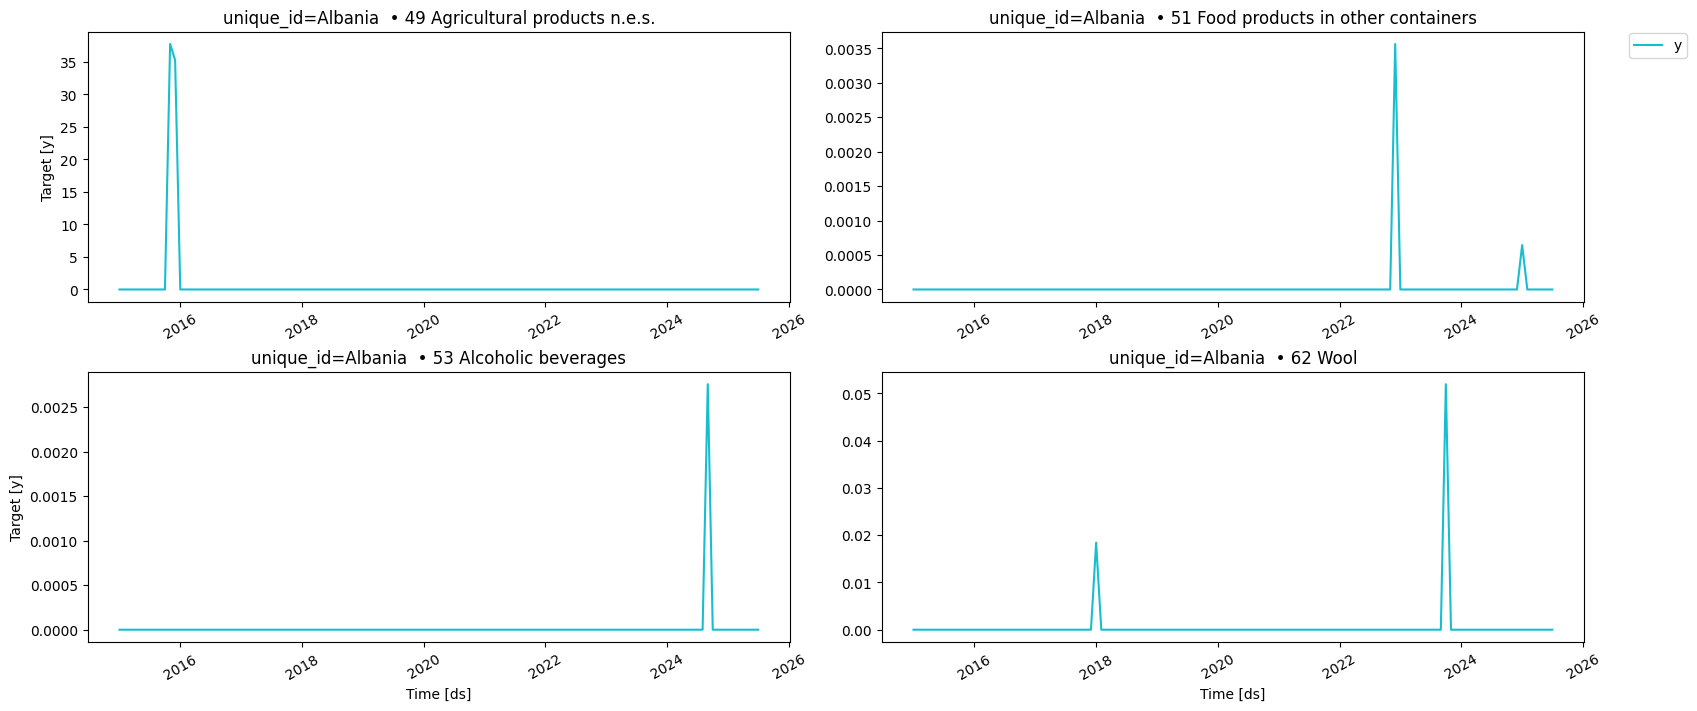

In [37]:
fig = plot_series(Y_df, max_ids=4, plot_random=False, max_insample_length=24 * 14)
fig

In [39]:
import lightgbm as lgb
from mlforecast.target_transforms import Differences

In [40]:
models = [lgb.LGBMRegressor(verbosity=-1)]

mlf = MLForecast(
    models=models, 
    freq='MS',                # monthly data, month start frequency
    target_transforms=[Differences([12])],  # 12-month difference for yearly seasonality
    lags=range(1, 13) 
)

In [41]:
"""cv_df = mlf.cross_validation(
    df=Y_df,
    h=24,
    n_windows=3,
)"""

'cv_df = mlf.cross_validation(\n    df=Y_df,\n    h=24,\n    n_windows=3,\n)'

In [43]:
cv_df = mlf.cross_validation(
    df=Y_df,
    h=24,
    n_windows=3,
    step_size=12,   # move forward 1 year per CV window
    refit=True,     # retrain per window (more realistic, slower)
)

In [53]:
cv_df[cv_df['unique_id'].str.contains("United States", na=False)]

,unique_id,ds,cutoff,y,LGBMRegressor
63816,"United States • 00 Whole fish, fresh, chilled ...",2021-08-01,2021-07-01,42.9750,40.262750
63817,"United States • 00 Whole fish, fresh, chilled ...",2021-09-01,2021-07-01,45.5917,60.261932
63818,"United States • 00 Whole fish, fresh, chilled ...",2021-10-01,2021-07-01,37.1670,40.839023
63819,"United States • 00 Whole fish, fresh, chilled ...",2021-11-01,2021-07-01,37.9248,44.116144
63820,"United States • 00 Whole fish, fresh, chilled ...",2021-12-01,2021-07-01,56.0616,38.108716
...,...,...,...,...,...
198235,United States • 99 Other products,2025-03-01,2023-07-01,88.1550,22.057898
198236,United States • 99 Other products,2025-04-01,2023-07-01,64.4741,31.594416
198237,United States • 99 Other products,2025-05-01,2023-07-01,91.2649,5.602222
198238,United States • 99 Other products,2025-06-01,2023-07-01,25.5543,28.881896


In [55]:
"""mlf = MLForecast(
    models=models,
    freq='MS',
    target_transforms=[Differences([12])],
    lags=range(1, 13),
)"""

mlf.fit(Y_df)

# Forecast next 18 months
future = mlf.predict(h=12)

In [56]:
future

,unique_id,ds,LGBMRegressor
0,Albania • 49 Agricultural products n.e.s.,2025-08-01,0.524459
1,Albania • 49 Agricultural products n.e.s.,2025-09-01,0.524459
2,Albania • 49 Agricultural products n.e.s.,2025-10-01,0.524459
3,Albania • 49 Agricultural products n.e.s.,2025-11-01,0.524459
4,Albania • 49 Agricultural products n.e.s.,2025-12-01,0.524459
...,...,...,...
33319,Åland Islands • 99 Other products,2026-03-01,0.524459
33320,Åland Islands • 99 Other products,2026-04-01,0.524459
33321,Åland Islands • 99 Other products,2026-05-01,0.524459
33322,Åland Islands • 99 Other products,2026-06-01,0.524459


In [66]:
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import rmse


In [67]:
from sklearn.metrics import r2_score
temp = cv_df[cv_df['unique_id'].str.contains("Fish fillet", na=False)]
r2 = r2_score(temp['y'], temp['LGBMRegressor'])
#ootmse = rmse(cv_df['y'], cv_df['LGBMRegressor'])
print(f"r2 using cross-validation: {r2:.1f}")

r2 using cross-validation: 0.6


In [63]:
cv_rmse = evaluate(
    cv_df.drop(columns='cutoff'),
    metrics=[rmse],
    agg_fn='mean',
)
print(f"RMSE using cross-validation: {cv_rmse['LGBMRegressor'].item():.1f}")

RMSE using cross-validation: 38.5


In [44]:
import matplotlib.pyplot as plt

In [46]:
def plot_cv(df, df_cv, uid, fname, last_n=24 * 14):
    cutoffs = df_cv.query('unique_id == @uid')['cutoff'].unique()
    fig, ax = plt.subplots(nrows=len(cutoffs), ncols=1, figsize=(14, 6), gridspec_kw=dict(hspace=0.8))
    for cutoff, axi in zip(cutoffs, ax.flat):
        df.query('unique_id == @uid').tail(last_n).set_index('ds').plot(ax=axi, title=uid, y='y')
        df_cv.query('unique_id == @uid & cutoff == @cutoff').set_index('ds').plot(ax=axi, title=uid, y='LGBMRegressor')
    fig.savefig(fname, bbox_inches='tight')
    plt.close()

In [28]:
#plot_cv(Y_df, cv_df, 'H1', 'figs/cross_validation__predictions.png')


In [ ]:
#pd.to_datetime(out[incoming_month],dayfirst=True).dt.to_period("M").dt.to_timestamp()

In [2]:
import os
import logging

import pandas as pd
from IPython.display import display



In [3]:
os.environ['PL_TRAINER_ENABLE_PROGRESS_BAR'] = '0'
logging.getLogger('pytorch_lightning').setLevel(logging.ERROR)

In [17]:
from neuralforecast import NeuralForecast 
from neuralforecast.auto import MLP, NBEATS, NHITS
from neuralforecast.losses.pytorch import MQLoss

In [18]:
from utilsforecast.plotting import plot_series



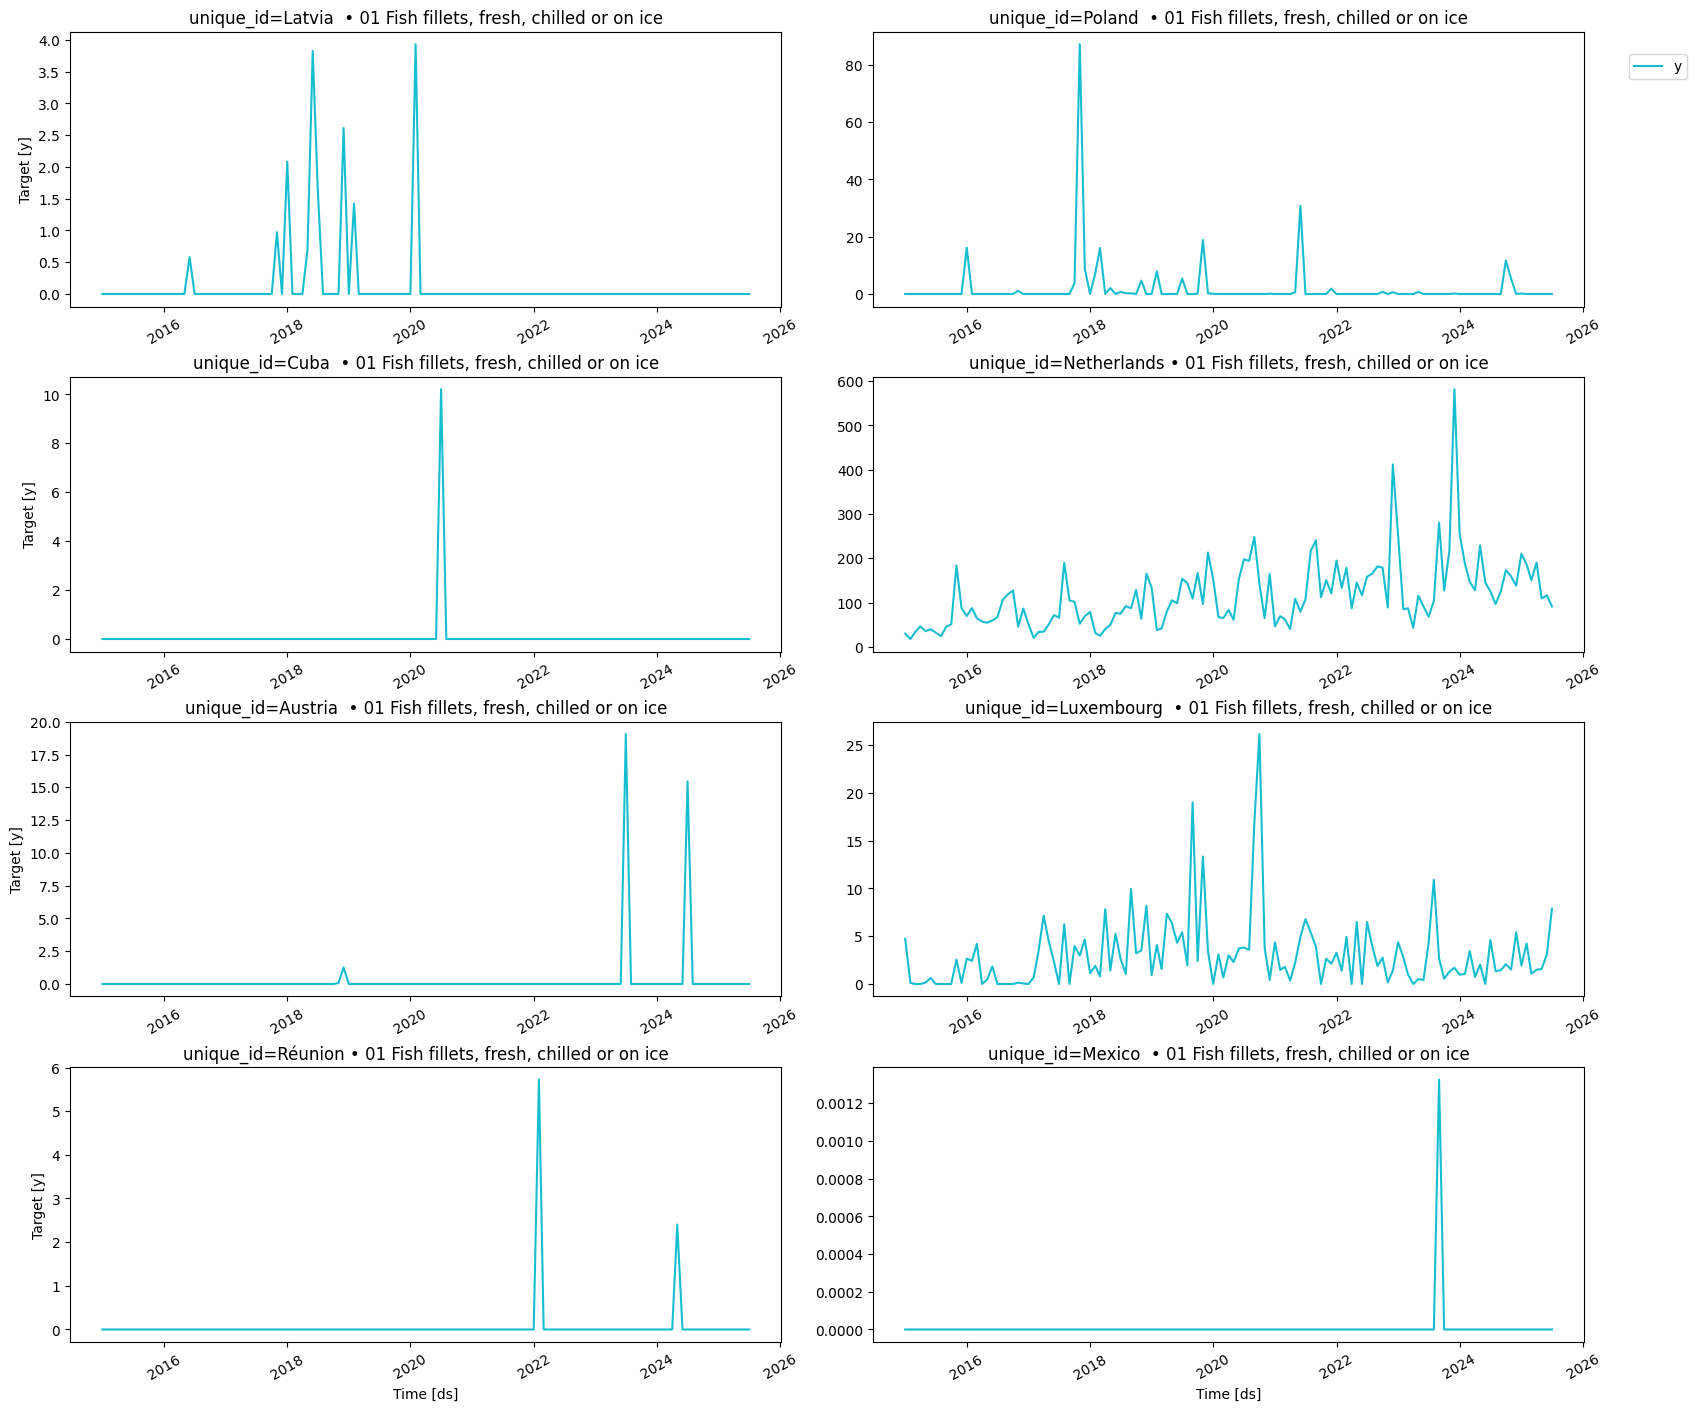

In [21]:
plot_series(Y_df[Y_df['unique_id'].str.contains("Fish fillet", na=False)])

In [22]:
horizon = 12 
models = [MLP(h=horizon, input_size=2*horizon, loss=MQLoss()), 
          NBEATS(h=horizon, input_size=2*horizon, loss=MQLoss()), 
          NHITS(h=horizon, input_size=2*horizon, loss=MQLoss()),]
nf = NeuralForecast(models=models, freq="MS")

[rank: 0] Seed set to 1
[rank: 0] Seed set to 1
[rank: 0] Seed set to 1


In [23]:
cv_df = nf.cross_validation(Y_df, n_windows=3, step_size=horizon, refit=1)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
You are using a CUDA device ('NVIDIA A100-PCIE-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name         | Type          | Params | Mode 
-------------------------------------------------------
0 | loss         | MQLoss        | 5      | train
1 | padder_train | ConstantPad1d | 0      | train
2 | scaler       | TemporalNorm  | 0      | train
3 | mlp          | ModuleList    | 1.1 M  | train
4 | out          | Linear        | 61.5 K | train
-------------------------------------------------------
1.1 M     Trainable params
5         Non-trainable params
1.1 M     Total params
4.547     Total estima

In [25]:
cv_df.head()


,unique_id,ds,cutoff,MLP-median,MLP-lo-90,MLP-lo-80,MLP-hi-80,MLP-hi-90,NBEATS-median,NBEATS-lo-90,NBEATS-lo-80,NBEATS-hi-80,NBEATS-hi-90,NHITS-median,NHITS-lo-90,NHITS-lo-80,NHITS-hi-80,NHITS-hi-90,y
0,Albania • 49 Agricultural products n.e.s.,2022-08-01,2022-07-01,0.000736,-0.006192,-0.020141,0.001746,0.054497,0.000770,-0.016754,-0.017719,0.005340,0.008424,0.000535,-0.026520,-0.018640,0.003677,0.004512,0.0
1,Albania • 49 Agricultural products n.e.s.,2022-09-01,2022-07-01,-0.001947,-0.016408,-0.019327,0.009894,0.048097,-0.000061,-0.023083,-0.008729,0.004822,0.013913,0.001274,-0.019400,-0.018759,0.002601,0.010819,0.0
2,Albania • 49 Agricultural products n.e.s.,2022-10-01,2022-07-01,0.001124,-0.004978,-0.002514,0.020325,0.059205,0.000614,-0.013128,-0.007356,0.000683,0.013684,0.001143,-0.018935,-0.015668,0.006143,0.008574,0.0
3,Albania • 49 Agricultural products n.e.s.,2022-11-01,2022-07-01,0.001201,-0.004408,-0.003945,0.001082,0.055350,-0.000003,-0.011542,-0.004719,0.007942,0.021270,0.001438,-0.015131,-0.014598,0.006079,0.012488,0.0
4,Albania • 49 Agricultural products n.e.s.,2022-12-01,2022-07-01,0.001258,-0.011329,-0.014185,0.000624,0.058280,-0.000449,-0.010534,-0.015015,0.009803,0.008452,0.001961,-0.009736,-0.012278,0.003812,0.010814,0.0


In [31]:
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import rmse
from sklearn.metrics import r2_score


In [33]:
evaluation_df = evaluate(cv_df.drop(columns='cutoff'), metrics=[rmse])
evaluation_df['best_model'] = evaluation_df.drop(columns=['metric', 'unique_id']).idxmin(axis=1)
evaluation_df

,unique_id,metric,MLP-median,NBEATS-median,NHITS-median,best_model
0,Albania • 49 Agricultural products n.e.s.,rmse,0.000861,0.002925,0.001166,MLP-median
1,Albania • 51 Food products in other containers,rmse,0.000927,0.003034,0.001156,MLP-median
2,Albania • 53 Alcoholic beverages,rmse,0.000982,0.003040,0.001339,MLP-median
3,Albania • 62 Wool,rmse,0.008683,0.009048,0.008459,NHITS-median
4,Albania • 69 Other textiles,rmse,0.000861,0.002925,0.001166,MLP-median
...,...,...,...,...,...,...
2772,Yemen • 72 Prod. of other chemical industries,rmse,0.102764,0.103304,0.102997,MLP-median
2773,Zambia • 83 Machinery and equipment,rmse,0.000861,0.002925,0.001166,MLP-median
2774,"Zambia • 89 Other manufacturing, n.e.s.",rmse,0.075553,0.075381,0.101135,NBEATS-median
2775,Zimbabwe • 83 Machinery and equipment,rmse,0.000861,0.002925,0.001166,MLP-median


In [35]:
from sklearn.metrics import r2_score
temp2 = cv_df[cv_df['unique_id'].str.contains("Fish fillet", na=False)]
r2 = r2_score(temp2['y'], temp2['MLP-median'])
#ootmse = rmse(cv_df['y'], cv_df['LGBMRegressor'])
print(f"r2 using cross-validation: {r2:.1f}")

r2 using cross-validation: 1.0


In [36]:
from sklearn.metrics import r2_score
temp2 = cv_df[cv_df['unique_id'].str.contains("Fish fillet", na=False)]
r2 = r2_score(temp2['y'], temp2['NBEATS-median'])
#ootmse = rmse(cv_df['y'], cv_df['LGBMRegressor'])
print(f"r2 using cross-validation: {r2:.1f}")#NHITS-median

r2 using cross-validation: 1.0


In [37]:
from sklearn.metrics import r2_score
temp2 = cv_df[cv_df['unique_id'].str.contains("Fish fillet", na=False)]
r2 = r2_score(temp2['y'], temp2['NHITS-median'])
#ootmse = rmse(cv_df['y'], cv_df['LGBMRegressor'])
print(f"r2 using cross-validation: {r2:.1f}")#NHITS-median

r2 using cross-validation: 0.9


In [43]:
#future2 = mlf.predict(h=12)

fcst = nf.predict(h=12)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


In [44]:
fcst.tail()

,unique_id,ds,MLP-median,MLP-lo-90,MLP-lo-80,MLP-hi-80,MLP-hi-90,NBEATS-median,NBEATS-lo-90,NBEATS-lo-80,NBEATS-hi-80,NBEATS-hi-90,NHITS-median,NHITS-lo-90,NHITS-lo-80,NHITS-hi-80,NHITS-hi-90
33319,Åland Islands • 99 Other products,2025-03-01,-0.000145,-0.001647,-0.002258,0.000556,0.012341,-0.003644,-0.006091,-0.001903,0.011632,0.012960,-0.001106,-0.003652,-0.005979,0.005692,0.009691
33320,Åland Islands • 99 Other products,2025-04-01,0.000218,0.000006,-0.003967,0.000294,0.021461,-0.006027,-0.005356,-0.002238,0.009689,0.024724,-0.002031,-0.005831,-0.008613,0.005956,0.015056
33321,Åland Islands • 99 Other products,2025-05-01,0.000138,-0.000869,-0.000717,0.000608,0.019511,-0.001798,-0.006764,-0.000115,0.012408,0.017762,-0.001036,-0.006754,-0.010876,0.006031,0.013759
33322,Åland Islands • 99 Other products,2025-06-01,0.000097,-0.003940,-0.002851,0.000615,0.014461,-0.006226,-0.008849,-0.006302,0.015726,0.020778,-0.000805,-0.005522,-0.014533,0.005480,0.014910
33323,Åland Islands • 99 Other products,2025-07-01,-0.000056,-0.010631,-0.000078,0.000219,0.014225,-0.004145,-0.006637,-0.002982,0.013493,0.021684,-0.000149,-0.005134,-0.014429,0.006458,0.016081


In [45]:
cv_df.ds.unique()

<DatetimeArray>
['2022-08-01 00:00:00', '2022-09-01 00:00:00', '2022-10-01 00:00:00',
 '2022-11-01 00:00:00', '2022-12-01 00:00:00', '2023-01-01 00:00:00',
 '2023-02-01 00:00:00', '2023-03-01 00:00:00', '2023-04-01 00:00:00',
 '2023-05-01 00:00:00', '2023-06-01 00:00:00', '2023-07-01 00:00:00',
 '2023-08-01 00:00:00', '2023-09-01 00:00:00', '2023-10-01 00:00:00',
 '2023-11-01 00:00:00', '2023-12-01 00:00:00', '2024-01-01 00:00:00',
 '2024-02-01 00:00:00', '2024-03-01 00:00:00', '2024-04-01 00:00:00',
 '2024-05-01 00:00:00', '2024-06-01 00:00:00', '2024-07-01 00:00:00',
 '2024-08-01 00:00:00', '2024-09-01 00:00:00', '2024-10-01 00:00:00',
 '2024-11-01 00:00:00', '2024-12-01 00:00:00', '2025-01-01 00:00:00',
 '2025-02-01 00:00:00', '2025-03-01 00:00:00', '2025-04-01 00:00:00',
 '2025-05-01 00:00:00', '2025-06-01 00:00:00', '2025-07-01 00:00:00']
Length: 36, dtype: datetime64[ns]

In [46]:
fcst.ds.unique()

<DatetimeArray>
['2024-08-01 00:00:00', '2024-09-01 00:00:00', '2024-10-01 00:00:00',
 '2024-11-01 00:00:00', '2024-12-01 00:00:00', '2025-01-01 00:00:00',
 '2025-02-01 00:00:00', '2025-03-01 00:00:00', '2025-04-01 00:00:00',
 '2025-05-01 00:00:00', '2025-06-01 00:00:00', '2025-07-01 00:00:00']
Length: 12, dtype: datetime64[ns]

In [47]:


last_ds = Y_df['ds'].max()
print("maxdate:",last_ds)
future_ds = pd.date_range(start=last_ds, periods=12, freq='MS', inclusive='neither')
futr_df = (
    Y_df[['unique_id']].drop_duplicates()
    .assign(key=1)
    .merge(pd.DataFrame({'key':1, 'ds':future_ds}), on='key')
    .drop('key', axis=1)
)

fcst = nf.predict(futr_df=futr_df,h=12)  # not required for your current models, but handy pattern


maxdate: 2025-07-01 00:00:00


ValueError: There are missing combinations of ids and times in `futr_df`.
You can run the `make_future_dataframe()` method to get the expected combinations or the `get_missing_future(futr_df)` method to get the missing combinations.